In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.xlsx', '.csv')):
            print(os.path.join(root, file))

/content/drive/MyDrive/Copy of xgboost_case_type_ready (1).xlsx
/content/drive/MyDrive/supreme_court_priority_prediction_dataset.xlsx
/content/drive/MyDrive/XGBoost_Case_Type_Model/training_history.csv
/content/drive/MyDrive/XGBoost_Case_Type_Model/test_classification_report.csv
/content/drive/MyDrive/XGBoost_Case_Type_Model/test_predictions.csv
/content/drive/MyDrive/XGBoost_Priority_Model/priority_training_history.csv
/content/drive/MyDrive/XGBoost_Priority_Model/priority_test_classification_report.csv
/content/drive/MyDrive/XGBoost_Priority_Model/priority_test_predictions.csv


In [3]:
file_path = "/content/drive/MyDrive/supreme_court_priority_prediction_dataset.xlsx"

import os
print(os.path.exists(file_path))

True


In [25]:
priority_model.save_model(
    "/content/drive/MyDrive/priority_model.json"
)

In [4]:
import pandas as pd

file_path = "/content/drive/MyDrive/supreme_court_priority_prediction_dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (18681, 27)

Columns:
['complexity_score', 'case_age', 'estimated_duration_days', 'hearing_count', 'adjournment_count', 'pending_references', 'judgment_complexity', 'workload_score', 'total_citations', 'cases_cited_count', 'statutes_cited_count', 'foreign_citations', 'number_of_parties', 'page_count', 'word_count', 'sentence_count', 'is_appeal', 'case_type_civil', 'case_type_constitutional', 'case_type_corporate', 'case_type_criminal', 'case_type_election', 'case_type_family', 'case_type_service', 'case_type_tax', 'case_type_uncategorized', 'assignment_priority']


,complexity_score,case_age,estimated_duration_days,hearing_count,adjournment_count,pending_references,judgment_complexity,workload_score,total_citations,cases_cited_count,...,case_type_civil,case_type_constitutional,case_type_corporate,case_type_criminal,case_type_election,case_type_family,case_type_service,case_type_tax,case_type_uncategorized,assignment_priority
0,0.278,27,180,0,5,0,0.066667,3.10,5,2,...,0,1,0,0,0,0,0,0,0,MEDIUM
1,0.811,51,120,0,2,0,0.173333,2.32,8,2,...,1,0,0,0,0,0,0,0,0,HIGH
2,0.186,53,132,0,0,0,0.166667,2.50,9,5,...,0,0,0,0,0,0,0,1,0,MEDIUM
3,0.974,7,108,4,4,2,0.160000,4.28,0,0,...,0,0,0,0,0,0,1,0,0,HIGH
4,0.106,38,180,1,0,0,0.620000,3.96,8,0,...,0,1,0,0,0,0,0,0,0,MEDIUM


In [5]:
print("Target distribution:")
print(df["assignment_priority"].value_counts())

print("\nTarget percentages:")
print(df["assignment_priority"].value_counts(normalize=True) * 100)

Target distribution:
assignment_priority
MEDIUM    6227
HIGH      6227
LOW       6227
Name: count, dtype: int64

Target percentages:
assignment_priority
MEDIUM    33.333333
HIGH      33.333333
LOW       33.333333
Name: proportion, dtype: float64


In [6]:
X = df.drop(columns=["assignment_priority"])
y = df["assignment_priority"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (18681, 26)
y shape: (18681,)


In [7]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded classes:", sorted(set(y_encoded)))

Classes: ['HIGH' 'LOW' 'MEDIUM']
Encoded classes: [np.int64(0), np.int64(1), np.int64(2)]


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (13076, 26)
Validation: (2802, 26)
Testing: (2803, 26)


In [9]:
print("Missing values in training data:")
print(X_train.isnull().sum())

Missing values in training data:
complexity_score            0
case_age                    0
estimated_duration_days     0
hearing_count               0
adjournment_count           0
pending_references          0
judgment_complexity         0
workload_score              0
total_citations             0
cases_cited_count           0
statutes_cited_count        0
foreign_citations           0
number_of_parties           0
page_count                  0
word_count                  0
sentence_count              0
is_appeal                   0
case_type_civil             0
case_type_constitutional    0
case_type_corporate         0
case_type_criminal          0
case_type_election          0
case_type_family            0
case_type_service           0
case_type_tax               0
case_type_uncategorized     0
dtype: int64


In [10]:
X_train = X_train.fillna(0)
X_val = X_val.fillna(0)
X_test = X_test.fillna(0)

In [11]:
!pip install -q xgboost

In [12]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.3.0


In [13]:
from xgboost import XGBClassifier

priority_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.02,
    max_depth=3,
    min_child_weight=10,
    subsample=0.70,
    colsample_bytree=0.70,
    gamma=0.2,
    reg_alpha=0.5,
    reg_lambda=5.0,

    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",

    random_state=42,
    n_jobs=-1
)

priority_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100
)

[0]	validation_0-mlogloss:1.09198	validation_1-mlogloss:1.09208
[100]	validation_0-mlogloss:0.68908	validation_1-mlogloss:0.69290
[200]	validation_0-mlogloss:0.54174	validation_1-mlogloss:0.55092
[300]	validation_0-mlogloss:0.46089	validation_1-mlogloss:0.47412
[400]	validation_0-mlogloss:0.40648	validation_1-mlogloss:0.42307
[499]	validation_0-mlogloss:0.36573	validation_1-mlogloss:0.38499


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=0.2,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.02, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=10, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=-1, num_class=3, ...)

In [14]:
from sklearn.metrics import accuracy_score, f1_score

train_predictions = priority_model.predict(X_train)
val_predictions = priority_model.predict(X_val)
test_predictions = priority_model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_predictions)
val_accuracy = accuracy_score(y_val, val_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

train_f1 = f1_score(y_train, train_predictions, average="macro")
val_f1 = f1_score(y_val, val_predictions, average="macro")
test_f1 = f1_score(y_test, test_predictions, average="macro")

print("=" * 50)
print("PRIORITY PREDICTION — XGBOOST")
print("=" * 50)
print(f"Training Accuracy:   {train_accuracy*100:.2f}%")
print(f"Validation Accuracy: {val_accuracy*100:.2f}%")
print(f"Test Accuracy:       {test_accuracy*100:.2f}%")
print()
print(f"Training Macro F1:   {train_f1*100:.2f}%")
print(f"Validation Macro F1: {val_f1*100:.2f}%")
print(f"Test Macro F1:       {test_f1*100:.2f}%")

PRIORITY PREDICTION — XGBOOST
Training Accuracy:   91.35%
Validation Accuracy: 89.65%
Test Accuracy:       88.37%

Training Macro F1:   91.41%
Validation Macro F1: 89.71%
Test Macro F1:       88.46%


In [15]:
train_predictions = priority_model.predict(X_train)

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

print(
    f"Training Accuracy: {train_accuracy * 100:.2f}%"
)

Training Accuracy: 91.35%


In [16]:
val_predictions = priority_model.predict(X_val)

val_accuracy = accuracy_score(
    y_val,
    val_predictions
)

print(
    f"Validation Accuracy: {val_accuracy * 100:.2f}%"
)

Validation Accuracy: 89.65%


In [17]:
test_predictions = priority_model.predict(X_test)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print(
    f"Test Accuracy: {test_accuracy * 100:.2f}%"
)

Test Accuracy: 88.37%


In [18]:
train_f1 = f1_score(
    y_train,
    train_predictions,
    average="macro"
)

val_f1 = f1_score(
    y_val,
    val_predictions,
    average="macro"
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print(f"Training Macro F1:   {train_f1 * 100:.2f}%")
print(f"Validation Macro F1: {val_f1 * 100:.2f}%")
print(f"Test Macro F1:       {test_f1 * 100:.2f}%")

Training Macro F1:   91.41%
Validation Macro F1: 89.71%
Test Macro F1:       88.46%


In [19]:
from sklearn.metrics import classification_report

In [20]:
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["LOW", "MEDIUM", "HIGH"]
    )
)

              precision    recall  f1-score   support

         LOW       0.92      0.91      0.91       934
      MEDIUM       0.93      0.89      0.91       934
        HIGH       0.81      0.86      0.83       935

    accuracy                           0.88      2803
   macro avg       0.89      0.88      0.88      2803
weighted avg       0.89      0.88      0.88      2803



In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

In [22]:
cm = confusion_matrix(
    y_test,
    test_predictions
)

print(cm)

[[847   0  87]
 [  0 827 107]
 [ 72  60 803]]


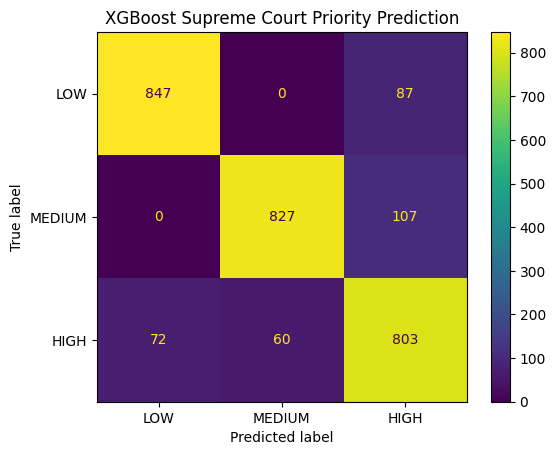

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["LOW", "MEDIUM", "HIGH"]
).plot()

plt.title("XGBoost Supreme Court Priority Prediction")
plt.show()

In [24]:
# Save the trained XGBoost priority prediction model

model_path = "/content/drive/MyDrive/priority_prediction_xgboost.json"

priority_model.save_model(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/drive/MyDrive/priority_prediction_xgboost.json
